## 股票

使用特徵: ['sma20', 'sma60', 'sma240', 'kama', 'adx', 'r2_20', 'r2_60', 'breakout_20', 'breakout_240', 'amount20', 'amount60', 'trust_in_5', 't_f_sync', 'yoy', 'yoy_ma3_bias']
使用特徵數量: 15
訓練集: (31897, 38)
驗證集: (8788, 38)
開始訓練 (Shooting High Mode)...
0:	test: 0.4664014	best: 0.4664014 (0)	total: 78ms	remaining: 12m 59s
100:	test: 0.5801865	best: 0.5910966 (93)	total: 4.08s	remaining: 6m 40s
200:	test: 0.5907666	best: 0.5965224 (116)	total: 7.8s	remaining: 6m 20s
300:	test: 0.5794705	best: 0.6001783 (202)	total: 11.6s	remaining: 6m 12s
400:	test: 0.5742570	best: 0.6001783 (202)	total: 16.1s	remaining: 6m 25s
500:	test: 0.5943405	best: 0.6001783 (202)	total: 23.8s	remaining: 7m 30s
600:	test: 0.5911094	best: 0.6039842 (506)	total: 31.6s	remaining: 8m 14s
700:	test: 0.5996285	best: 0.6056495 (679)	total: 39.6s	remaining: 8m 45s
800:	test: 0.5716124	best: 0.6056495 (679)	total: 47.5s	remaining: 9m 5s
900:	test: 0.5622128	best: 0.6056495 (679)	total: 55.1s	remaining: 9m 15s
1000:	test: 0.5679511	

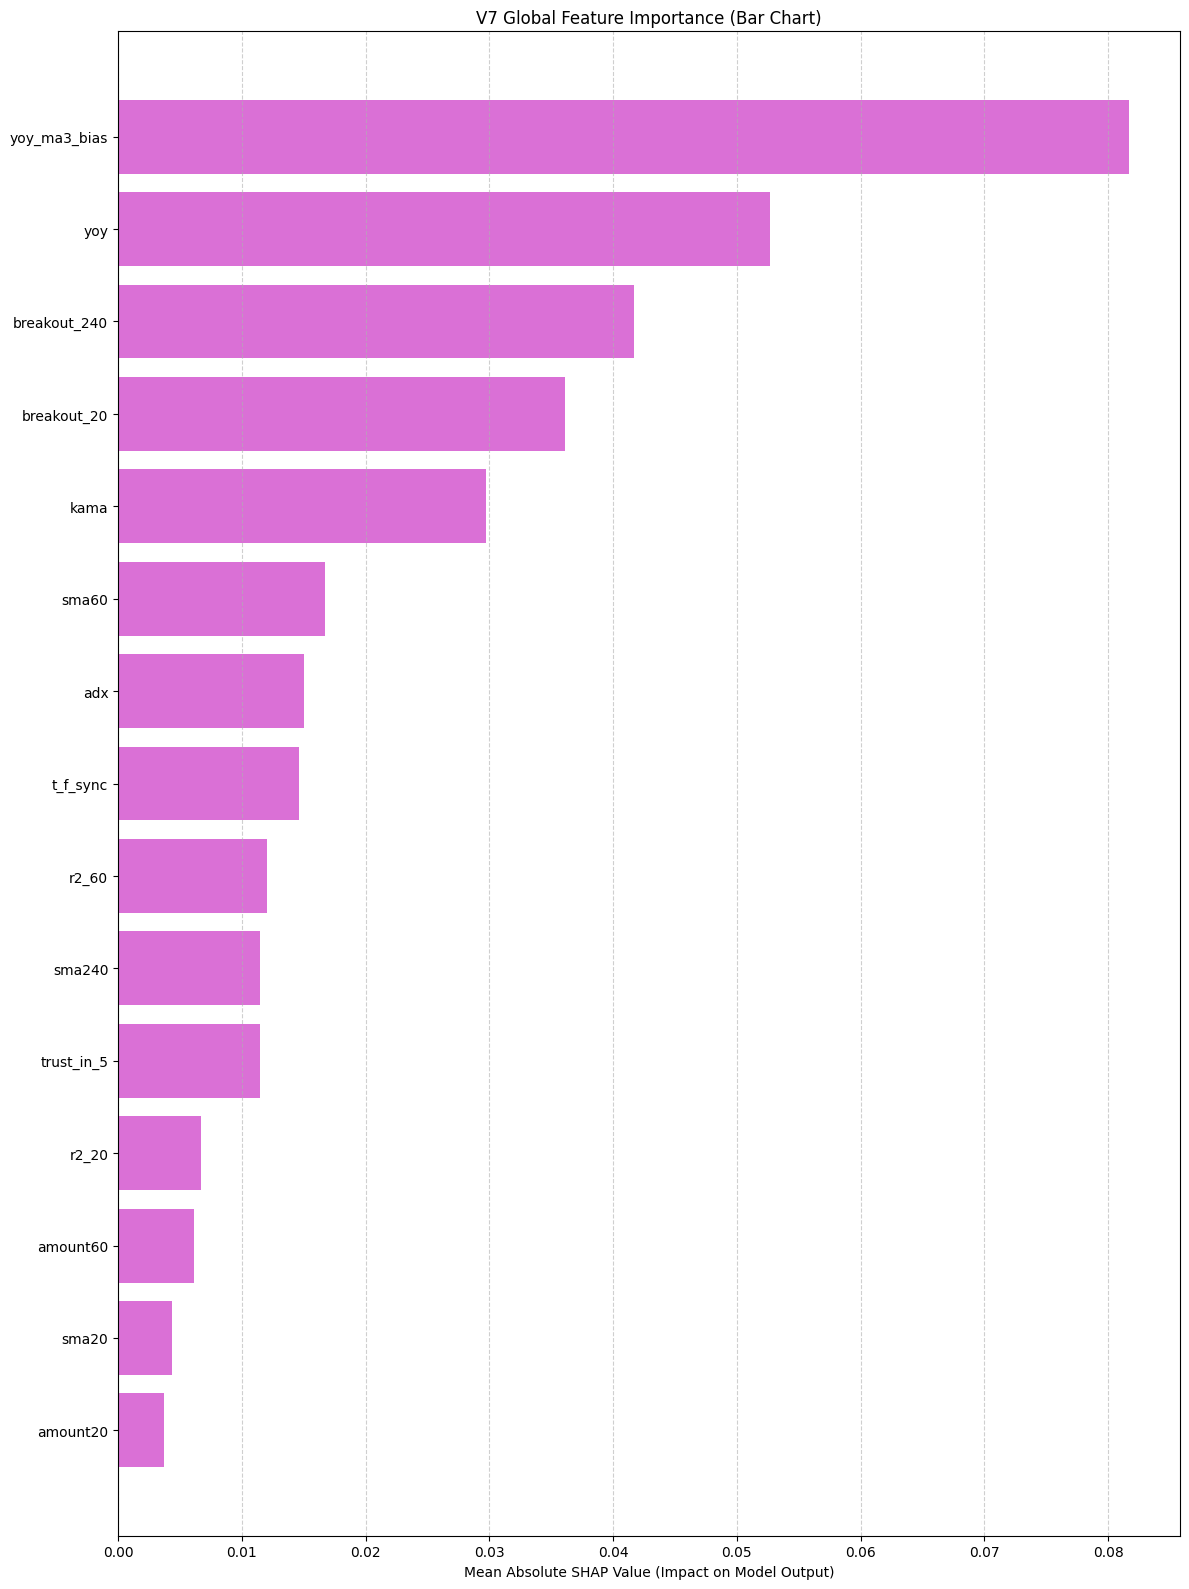

繪製 SHAP Summary Plot (蜂群圖)...


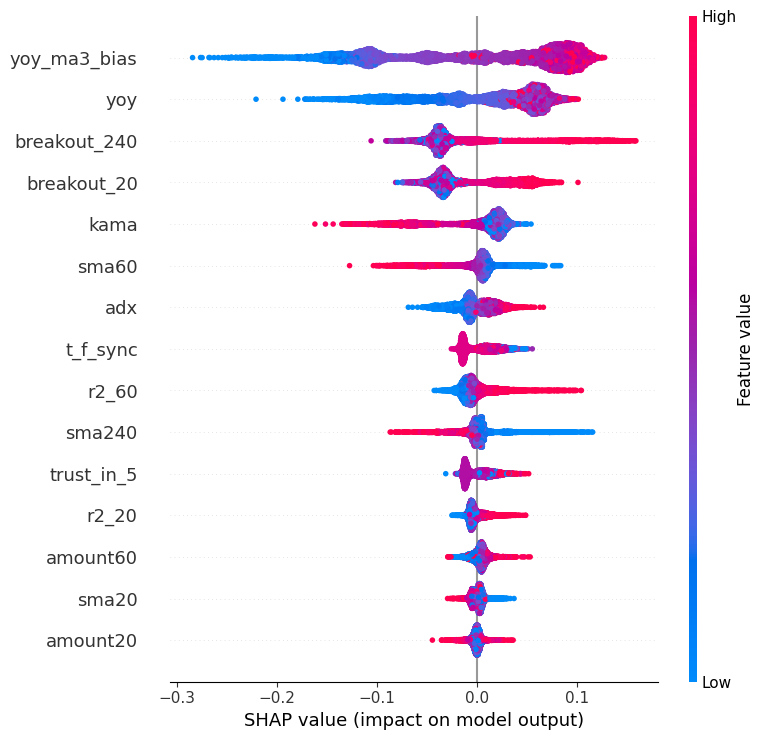

--- SHAP 重要性清單 (由高到低) ---
yoy_ma3_bias: 0.0817
yoy: 0.0527
breakout_240: 0.0417
breakout_20: 0.0361
kama: 0.0297
sma60: 0.0167
adx: 0.0150
t_f_sync: 0.0146
r2_60: 0.0121
sma240: 0.0115
trust_in_5: 0.0114
r2_20: 0.0067
amount60: 0.0061
sma20: 0.0043
amount20: 0.0037


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from catboost import Pool, CatBoostRanker
import shap  # 新增引用

%matplotlib inline
import matplotlib.pyplot as plt

# 假設妳的 ipynb 存在專案根目錄，data 在子目錄
df = pd.read_csv(r'c:\Users\Lynn610\Documents\kitsune_stock_system\data\features\train_v17.csv') 
df['date'] = pd.to_datetime(df['date'])

# 資料準備
df = df.sort_values(['date', 'id']).reset_index(drop=True)

col =[ col for col in df.columns]

# --- 1. 資料準備與設定 ---

X_col = ["sma20", "sma60", "sma240", "kama", "adx", "r2_20", "r2_60", "breakout_20", "breakout_240", 
         "amount20", "amount60", "trust_in_5", "t_f_sync", "yoy", "yoy_ma3_bias"]

y_col = 'label'
group_col = 'date'

print(f"使用特徵: {X_col}")
print(f"使用特徵數量: {len(X_col)}")

# 時間序列切分
dates = df['date'].unique()
split_idx = int(len(dates) * 0.8)
split_date = dates[split_idx]

train_df = df[df['date'] < split_date]
test_df = df[df['date'] >= split_date]

print(f"訓練集: {train_df.shape}")
print(f"驗證集: {test_df.shape}")

# 建立 Pool
train_pool = Pool(
    data=train_df[X_col],
    label=train_df[y_col],
    group_id=train_df[group_col].astype('category').cat.codes
)

test_pool = Pool(
    data=test_df[X_col],
    label=test_df[y_col],
    group_id=test_df[group_col].astype('category').cat.codes
)

# --- 2. 訓練模型 ---
model = CatBoostRanker(
    iterations=10000,
    learning_rate=0.005,
    depth=6,
    loss_function='YetiRank',
    eval_metric='NDCG:top=5',
    custom_metric=['PrecisionAt:top=5'],
    verbose=100,
    random_seed=42,
    early_stopping_rounds=1000,
)

print("開始訓練 (Shooting High Mode)...")
model.fit(train_pool, eval_set=test_pool, plot=False)

# --- 3. SHAP 計算 ---
shap_results = model.get_feature_importance(data=test_pool, type='ShapValues')

# 移除最後一欄 (Base Value)，保留特徵貢獻值
shap_values = shap_results[:, :-1]

# 計算平均絕對重要性 (給長條圖用)
shap_importance = np.abs(shap_values).mean(axis=0)
sorted_idx = shap_importance.argsort()

# --- 4. 繪圖 A: 傳統特徵重要性 (長條圖) ---
plt.figure(figsize=(12, 16))
plt.barh(range(len(sorted_idx)), shap_importance[sorted_idx], color='orchid', align='center')
plt.yticks(range(len(sorted_idx)), [X_col[i] for i in sorted_idx])
plt.xlabel('Mean Absolute SHAP Value (Impact on Model Output)')
plt.title('V7 Global Feature Importance (Bar Chart)')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# --- 5. 繪圖 B: SHAP Summary Plot (蜂群圖) --- [新增部分]
print("繪製 SHAP Summary Plot (蜂群圖)...")
plt.figure() 
# shap_values: 每個樣本的 SHAP 值
# test_df[X_col]: 原始特徵數值 (用於決定點的顏色，紅高藍低)
shap.summary_plot(shap_values, test_df[X_col], show=True)

# --- 6. 印出清單 ---
print("--- SHAP 重要性清單 (由高到低) ---")
for i in sorted_idx[::-1]:
    print(f"{X_col[i]}: {shap_importance[i]:.4f}")